# ChurnBoost AI – Exploratory Data Analysis
Understanding the UCI Online Retail II data before modelling: what is in it, how dirty it is, and what separates churned from retained customers.

Figures are also saved to `reports/`.

In [1]:
import sys; sys.path.insert(0, "..")
from pathlib import Path
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from src.data_loader import get_transactions, load_raw, clean
from src.features import build_dataset, FEATURES

sns.set_theme(style="whitegrid", palette=["#25586b", "#b4372c", "#d9962b", "#3b8b6e"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
REPORTS = Path("../reports"); REPORTS.mkdir(exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(REPORTS / f"{name}.png", dpi=160); plt.show()

## 1. Raw data and cleaning

In [2]:
raw = load_raw()
print(raw.shape); raw.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


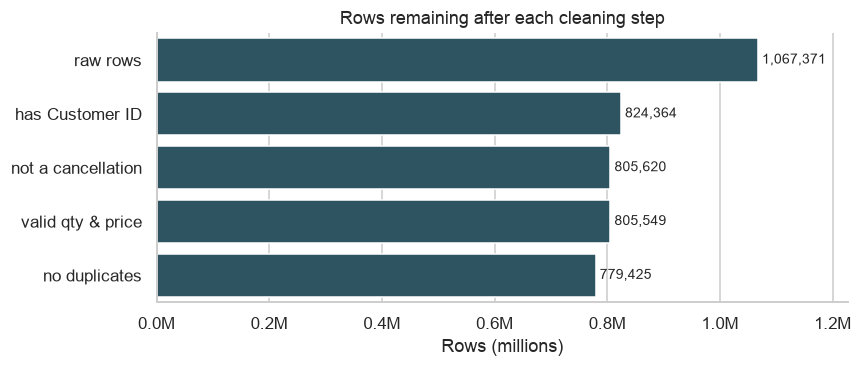

In [3]:
steps = {"raw rows": len(raw)}
d = raw.dropna(subset=["Customer ID"]); steps["has Customer ID"] = len(d)
d = d[~d["Invoice"].astype(str).str.startswith("C")]; steps["not a cancellation"] = len(d)
d = d[(d["Quantity"] > 0) & (d["Price"] > 0)]; steps["valid qty & price"] = len(d)
d = d.drop_duplicates(); steps["no duplicates"] = len(d)
s = pd.Series(steps)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=s.values, y=s.index, ax=ax, color="#25586b")
for i, v in enumerate(s.values): ax.text(v, i, f" {v:,}", va="center", fontsize=9)
ax.set_title("Rows remaining after each cleaning step"); ax.set_xlim(0, s.max() * 1.15)
ax.set_ylabel(""); ax.set_xlabel("Rows (millions)"); ax.xaxis.set_major_formatter(lambda v, _: f"{v/1e6:.1f}M")
save("01_cleaning_funnel")

In [4]:
df = get_transactions()
print(f"{len(df):,} rows | {df['Customer ID'].nunique():,} customers | {df['Invoice'].nunique():,} invoices")
print(f"{df['InvoiceDate'].min():%d %b %Y} -> {df['InvoiceDate'].max():%d %b %Y}")
df.describe(include="all").T.head(10)

779,425 rows | 5,878 customers | 36,969 invoices
01 Dec 2009 -> 09 Dec 2011


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,779425.0,NaN,NaN,NaN,537426.828586,489434.0,514483.0,536754.0,561995.0,581587.0,26901.629627
StockCode,779425,4631,85123A,5023,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,779425,5283,WHITE HANGING HEART T-LIGHT HOLDER,5016,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,779425.0,NaN,NaN,NaN,13.48937,1.0,2.0,6.0,12.0,80995.0,145.855814
InvoiceDate,779425,NaN,NaN,NaN,2011-01-03 01:44:42.593476,2009-12-01 07:45:00,2010-07-02 14:39:00,2010-12-02 14:09:00,2011-08-01 13:44:00,2011-12-09 12:50:00,NaN
Price,779425.0,NaN,NaN,NaN,3.218488,0.001,1.25,1.95,3.75,10953.5,29.67614
Customer ID,779425.0,NaN,NaN,NaN,15320.360461,12346.0,13971.0,15247.0,16794.0,18287.0,1695.692775
Country,779425,41,United Kingdom,700388,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revenue,779425.0,NaN,NaN,NaN,22.291823,0.001,4.95,12.48,19.8,168469.6,227.427075


## 2. Sales over time and geography

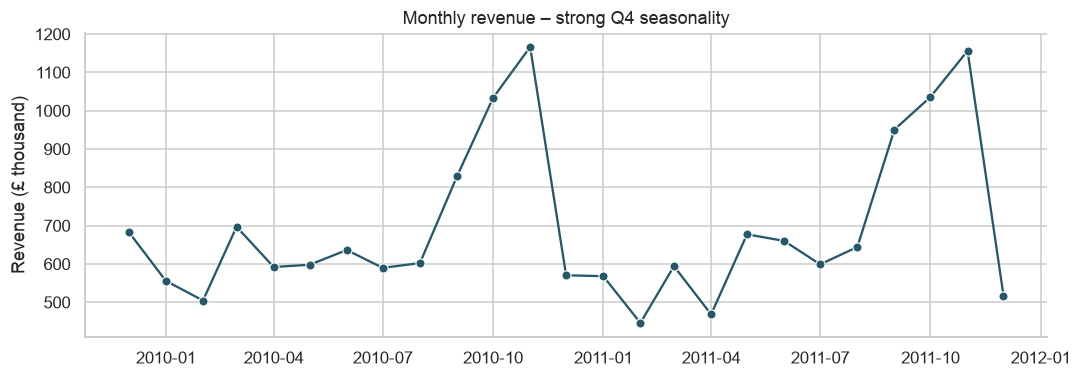

In [5]:
monthly = df.set_index("InvoiceDate")["Revenue"].resample("MS").sum()
fig, ax = plt.subplots(figsize=(10, 3.6))
sns.lineplot(x=monthly.index, y=monthly.values / 1e3, marker="o", ax=ax)
ax.set_ylabel("Revenue (£ thousand)"); ax.set_xlabel(""); ax.set_title("Monthly revenue – strong Q4 seasonality")
save("02_monthly_revenue")

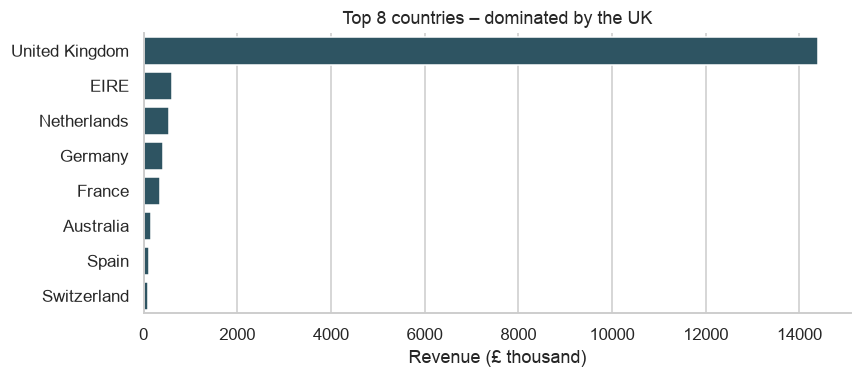

In [6]:
top = df.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(8)
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.barplot(x=top.values / 1e3, y=top.index, ax=ax, color="#25586b")
ax.set_xlabel("Revenue (£ thousand)"); ax.set_ylabel(""); ax.set_title("Top 8 countries – dominated by the UK")
save("03_top_countries")

## 3. RFM features and the churn label
Built from purchases before the cutoff date; churn = no purchase in the following 90 days.

In [7]:
data, cutoff = build_dataset(df)
print(f"cutoff: {cutoff.date()} | customers: {len(data):,} | churn rate: {data['churn'].mean():.1%}")
data[FEATURES + ["churn"]].describe().T.round(2)

cutoff: 2011-09-10 | customers: 5,281 | churn rate: 56.6%


,count,mean,std,min,25%,50%,75%,max
recency,5281.0,206.81,175.03,0.0,49.00,163.00,326.00,647.00
frequency,5281.0,5.75,11.46,1.0,1.00,3.00,6.00,309.00
monetary,5281.0,2637.86,12225.54,2.9,318.24,783.58,2078.54,456780.49
tenure,5281.0,431.32,180.52,0.0,311.00,473.00,586.00,647.00
avg_order_value,5281.0,369.29,538.21,2.9,174.67,276.86,409.72,14844.77
avg_days_between_orders,5281.0,160.64,162.11,0.0,44.43,91.33,231.00,647.00
n_products,5281.0,74.36,104.97,1.0,18.00,41.00,92.00,2182.00
churn,5281.0,0.57,0.50,0.0,0.00,1.00,1.00,1.00


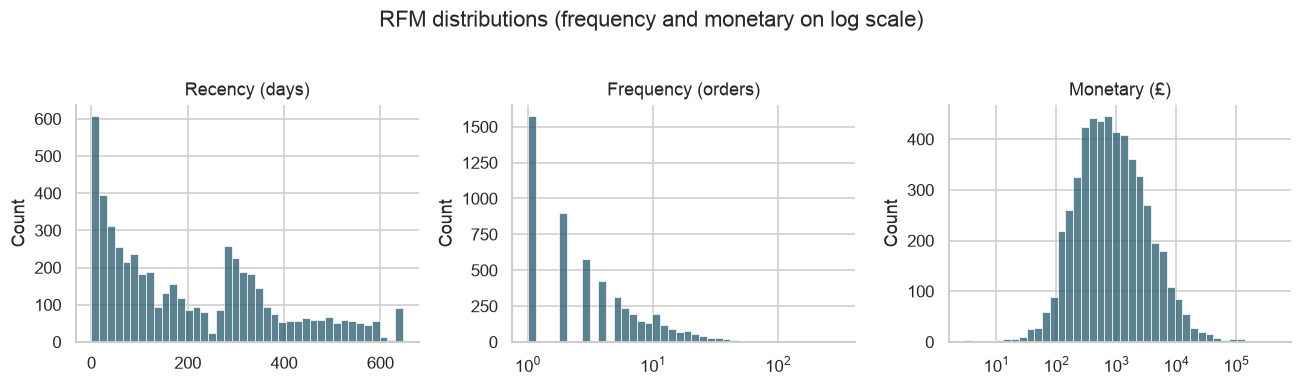

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col, title in zip(axes, ["recency", "frequency", "monetary"], ["Recency (days)", "Frequency (orders)", "Monetary (£)"]):
    sns.histplot(data[col], bins=40, ax=ax, log_scale=col != "recency", color="#25586b")
    ax.set_title(title); ax.set_xlabel("")
fig.suptitle("RFM distributions (frequency and monetary on log scale)", y=1.03)
save("04_rfm_distributions")

## 4. What separates churned from retained customers?

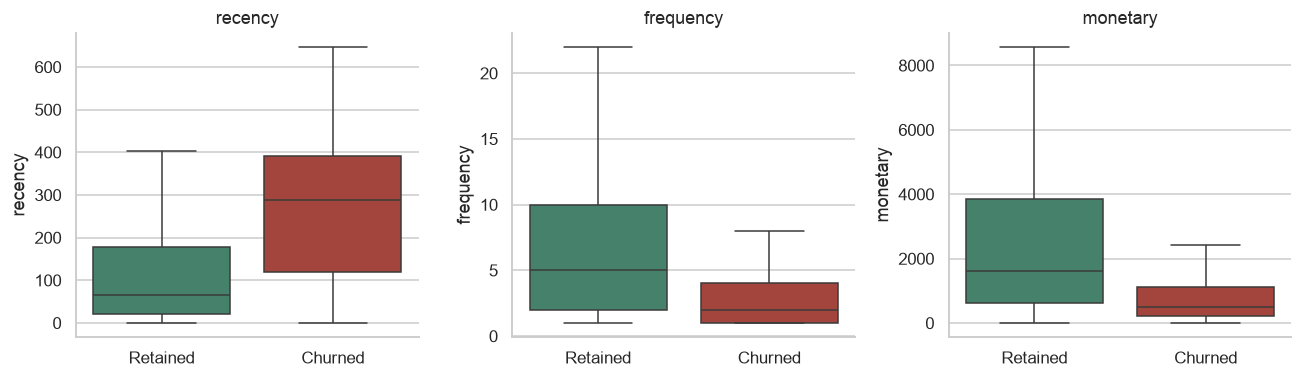

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col in zip(axes, ["recency", "frequency", "monetary"]):
    sns.boxplot(data=data, x="churn", y=col, hue="churn", legend=False, ax=ax, showfliers=False,
                palette={0: "#3b8b6e", 1: "#b4372c"})
    ax.set_xticks([0, 1], ["Retained", "Churned"]); ax.set_xlabel(""); ax.set_title(col)
save("05_rfm_by_churn")

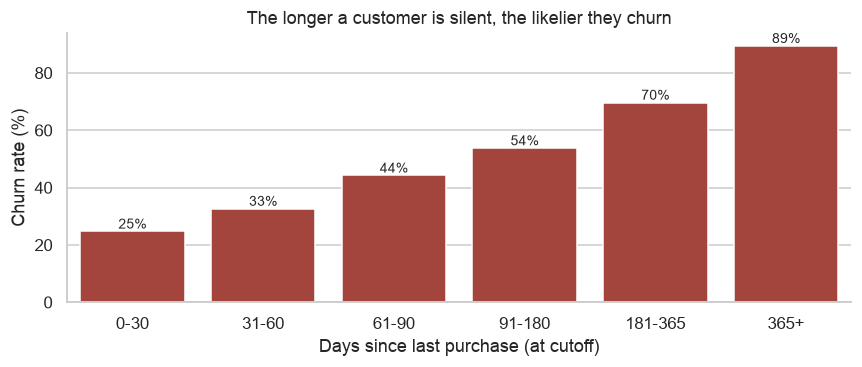

In [10]:
data["recency_bucket"] = pd.cut(data["recency"], [-1, 30, 60, 90, 180, 365, 1000],
                                labels=["0-30", "31-60", "61-90", "91-180", "181-365", "365+"])
rate = data.groupby("recency_bucket", observed=True)["churn"].mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#b4372c")
for i, v in enumerate(rate.values): ax.text(i, v, f"{v:.0f}%", ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Days since last purchase (at cutoff)"); ax.set_ylabel("Churn rate (%)"); ax.set_title("The longer a customer is silent, the likelier they churn")
save("06_churn_by_recency")

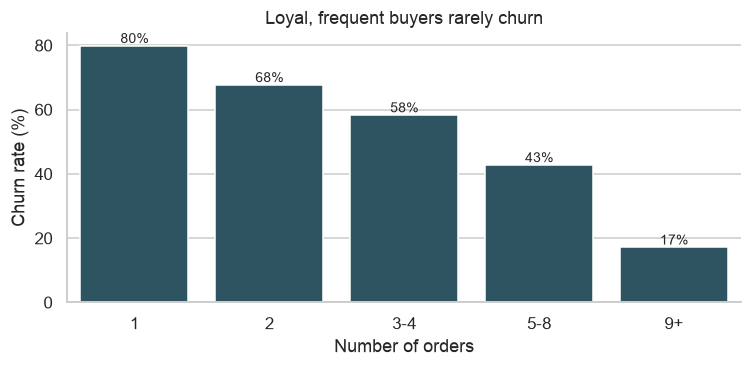

In [11]:
data["freq_bucket"] = pd.cut(data["frequency"], [0, 1, 2, 4, 8, 1000], labels=["1", "2", "3-4", "5-8", "9+"])
rate = data.groupby("freq_bucket", observed=True)["churn"].mean() * 100
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#25586b")
for i, v in enumerate(rate.values): ax.text(i, v, f"{v:.0f}%", ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Number of orders"); ax.set_ylabel("Churn rate (%)"); ax.set_title("Loyal, frequent buyers rarely churn")
save("07_churn_by_frequency")

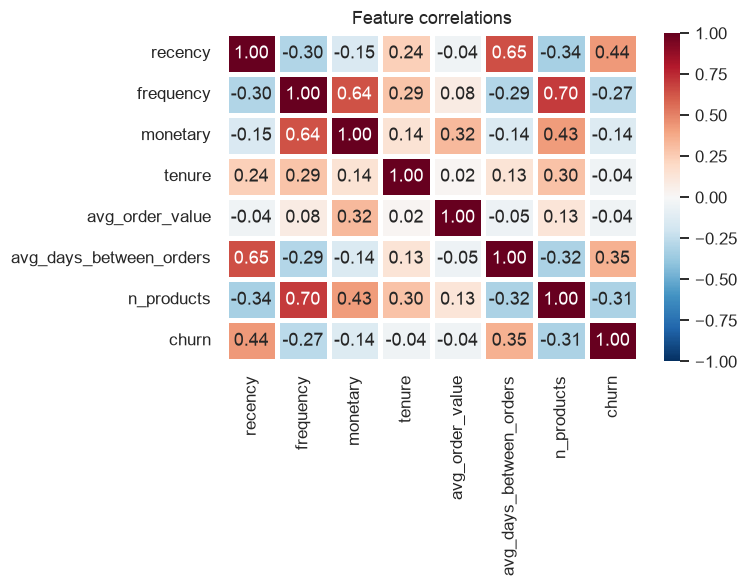

In [12]:
corr = data[FEATURES + ["churn"]].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, linewidths=2, linecolor="white")
ax.set_title("Feature correlations")
save("08_correlation")

## 5. Class balance
Churn is the majority class here, so imbalance is mild – which is why class-weight tuning has only a small effect.

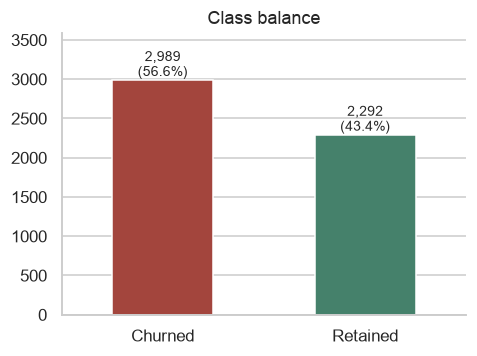

In [13]:
counts = data["churn"].map({0: "Retained", 1: "Churned"}).value_counts()
fig, ax = plt.subplots(figsize=(4.5, 3.4))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette={"Retained": "#3b8b6e", "Churned": "#b4372c"}, legend=False, ax=ax, width=0.5)
for i, v in enumerate(counts.values): ax.text(i, v, f"{v:,}\n({v/len(data):.1%})", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, counts.max() * 1.2); ax.set_xlabel(""); ax.set_title("Class balance")
save("09_class_balance")

## 6. Takeaways
- Recency is the strongest signal: customers silent for months are far more likely to churn.
- Frequency and spend both lower churn risk; one-time buyers churn the most.
- Revenue is highly seasonal (Q4 peak), so a fixed 90-day label window can mislabel seasonal buyers.
- Classes are roughly balanced, so beyond class weights the main modelling gains come from tuning tree and regularisation parameters.